# Visualizing fire scars through false color in Los Angeles

Author: Kelly Loo

GitHub Repository: [Repo Link](https://github.com/kloo49/eds220-hwk4-kloo)

# About
### Purpose:
We are interested in using Landsat8 bands data to create a false color imagery in order to see fire scars for the Eaton and Palisades fires in Los Angeles in 2025. These were the two most devasting fires for the season. We create a false color map to show the scars.

### Highlights:
- Exploration of data with `geopandas` and `xarray`
- Cleaning geospatial data
- Subsetting `rioxarray` data
- Plotting geospatial data with layers

### About the data:
- CAL FIRE Fire perimeter data [Metadata](https://calfire-forestry.maps.arcgis.com/home/item.html?id=a31aa1efe1d6466f8530b501c30ab00a#overview)
    - I obtained fire perimeter data from CAL FIRE. It includes the name, geometry, year, and other information about the fire.
    - This is a shape file.
- Landsat8
    - Landsat8 data has 5 bands (red, green, blue, SWIR, and NIR). The dataset I'm using for this analysis is already clipped to the Los Angeles area encompassing the Eaton and Palisades fire.
#### References:
U.S. Geological Survey. (2025). *Landsat 8*. U.S. Geological Survey. [Accessed Nov 18, 2026]\
Wallin, Kimberly. (2026). *Fire Perimeters*. California Department of Forestry and Fire Protection. [Accessed Nov 18, 2026]


## 1. Loading data

In [106]:
# Import packages
import os              
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt

In [107]:
# Import fire perimeter
perimeter = gpd.read_file(os.path.join('data','fire25_1.gdb'))

# Read in netCDF file
landsat = xr.open_dataset(os.path.join('data','landsat8-2025-02-23-palisades-eaton.nc'))

## Fire perimeter data exploration 


<Axes: >

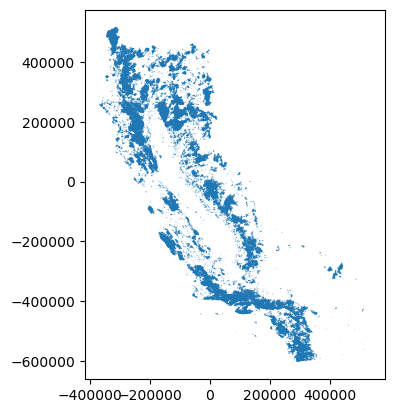

In [108]:
# Preliminary visualization
perimeter.plot()

In [109]:
# Check CRS
perimeter.crs

<Projected CRS: EPSG:3310>
Name: NAD83 / California Albers
Axis Info [cartesian]:
- X[east]: Easting (metre)
- Y[north]: Northing (metre)
Area of Use:
- name: United States (USA) - California.
- bounds: (-124.45, 32.53, -114.12, 42.01)
Coordinate Operation:
- name: California Albers
- method: Albers Equal Area
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [110]:
# Check first 5 rows
perimeter.head()

,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,INC_NUM,IRWINID,ALARM_DATE,CONT_DATE,C_METHOD,CAUSE,OBJECTIVE,COMPLEX_ID,COMPLEX_NAME,COMMENTS,FIRE_NUM,Shape_Length,Shape_Area,GlobalID,geometry
0,2025.0,CA,USF,LPF,GIFFORD,00002181,{08A6358F-8301-4093-9988-E265C8F6F0A9},2025-08-01 00:00:00+00:00,2025-10-14 00:00:00+00:00,3,14,1.0,None,None,None,None,257388.320379,5.326211e+08,{E87207FF-BD3D-4836-8A89-AD218A20B17E},"MULTIPOLYGON (((-35131.146 -302750.005, -35107..."
1,2025.0,CA,USF,LPF,MADRE,00001817,{1AB682F7-CC0F-4DCE-87A4-FA4A9B67AB05},2025-07-02 00:00:00+00:00,2025-07-26 00:00:00+00:00,7,14,1.0,None,None,None,None,191846.167384,3.269014e+08,{C59C71E2-F79F-440B-8C84-48058988F3CF},"MULTIPOLYGON (((-4405.284 -313794.721, -4405.4..."
2,2025.0,CA,USF,SNF,GARNET,00001684,{68B988A1-C190-4F0C-9BEA-A658D389D167},2025-08-24 00:00:00+00:00,2025-10-23 00:00:00+00:00,3,1,1.0,None,None,None,None,234717.355087,2.428892e+08,{DDD0B278-7655-4F20-829D-FEEEF1DC935F},"MULTIPOLYGON (((89617.826 -122364.580, 89614.9..."
3,2025.0,CA,CDF,FKU,SALT,00018739,{7F4A1474-6439-44F3-8F0D-083DCFD33639},2025-09-02 00:00:00+00:00,2025-09-17 00:00:00+00:00,7,1,1.0,None,None,Park incident clipped out per BEU,None,90080.360959,1.034115e+08,{6817A72C-90CF-4CD4-8F26-2B9622F1F140},"MULTIPOLYGON (((-31970.799 -229822.278, -31947..."
4,2025.0,CA,CDF,LDF,PALISADES,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},2025-01-07 00:00:00+00:00,2025-01-31 00:00:00+00:00,7,14,1.0,None,None,None,None,116028.197349,9.489426e+07,{73730F90-5D60-4850-98C2-2431C4284CD7},"MULTIPOLYGON (((136696.228 -441776.379, 136683..."


In [111]:
# Check datatypes
perimeter.dtypes

YEAR_                       float64
STATE                        object
AGENCY                       object
UNIT_ID                      object
FIRE_NAME                    object
INC_NUM                      object
IRWINID                      object
ALARM_DATE      datetime64[ns, UTC]
CONT_DATE       datetime64[ns, UTC]
C_METHOD                      int64
CAUSE                         int64
OBJECTIVE                   float64
COMPLEX_ID                   object
COMPLEX_NAME                 object
COMMENTS                     object
FIRE_NUM                     object
Shape_Length                float64
Shape_Area                  float64
GlobalID                     object
geometry                   geometry
dtype: object

The data is inclusive for California only. The CRS is EPSG:3310, and is geographic. I will be projecting the fire perimeter data to match the Landsat data.

In [112]:
# Clean the data
perimeter.columns = perimeter.columns.str.lower()
perimeter.rename(columns={'year_':'year'}, inplace=True)
perimeter.columns

Index(['year', 'state', 'agency', 'unit_id', 'fire_name', 'inc_num', 'irwinid',
       'alarm_date', 'cont_date', 'c_method', 'cause', 'objective',
       'complex_id', 'complex_name', 'comments', 'fire_num', 'shape_length',
       'shape_area', 'globalid', 'geometry'],
      dtype='object')

In [113]:
# Subset for Eaton and Palisades in 2025
eaton_perimeter = perimeter[(perimeter['fire_name'] == 'EATON') & (perimeter['year'] == 2025)]
palisades_perimeter = perimeter[(perimeter['fire_name'] == 'PALISADES') & (perimeter['year'] == 2025)]

In [114]:
# Join two geopandas dataframe into one
fire_perimeter = pd.concat([eaton_perimeter, palisades_perimeter])
fire_perimeter

,year,state,agency,unit_id,fire_name,inc_num,irwinid,alarm_date,cont_date,c_method,cause,objective,complex_id,complex_name,comments,fire_num,shape_length,shape_area,globalid,geometry
7,2025.0,CA,CDF,LAC,EATON,00009087,{72660ADC-B5EF-4D96-A33F-B4EA3740A4E3},2025-01-08 00:00:00+00:00,2025-01-31 00:00:00+00:00,7,14,1.0,None,None,None,None,86677.545056,5.688367e+07,{D8DCB0E7-0AD6-46A4-901A-86D777BB09AF},"MULTIPOLYGON (((175062.878 -425909.927, 175066..."
4,2025.0,CA,CDF,LDF,PALISADES,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},2025-01-07 00:00:00+00:00,2025-01-31 00:00:00+00:00,7,14,1.0,None,None,None,None,116028.197349,9.489426e+07,{73730F90-5D60-4850-98C2-2431C4284CD7},"MULTIPOLYGON (((136696.228 -441776.379, 136683..."


## 3. Landsat data exploration


In [115]:
landsat

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

In [116]:
landsat.dtypes

Frozen({'red': dtype('float32'), 'green': dtype('float32'), 'blue': dtype('float32'), 'nir08': dtype('float32'), 'swir22': dtype('float32'), 'spatial_ref': dtype('int64')})

There are 6 variables: `red`, `green`, `blue`, `nir08`, `swir22`, and `spatial_ref`. The first 5 are bands in Landsat8. `spatial_ref` is the spatial data with CRS information.\
The 2 dimensions are `x` and `y`.\
The coordinates of `x` and `y` are for location, and `time` is a datetime.

## 4. Restoring geospatial information


In [117]:
# Use rio.crs to print CRS
# doesn't return anything, must not be a geospatial object
landsat.rio.crs

In [118]:
# Access CRS via spatial_ref variable
landsat['spatial_ref'].crs_wkt

'PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]'

In [119]:
# Recover geospatial information with rio.write_crs()
landsat = landsat.rio.write_crs(landsat['spatial_ref'].crs_wkt)

In [120]:
# Check CRS again
landsat.rio.crs

CRS.from_wkt('PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]')

## 5. True Color Image

/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


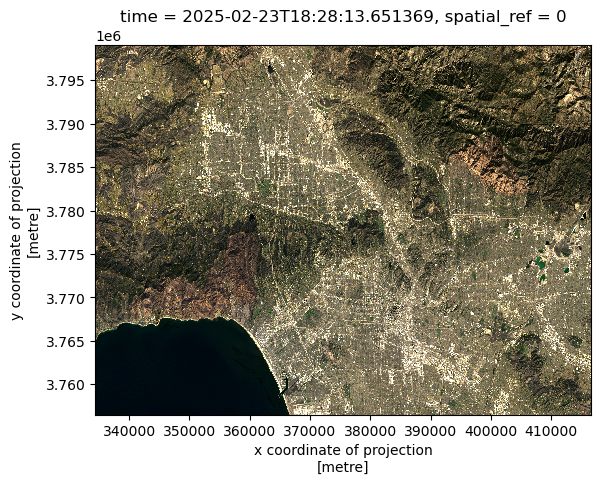

In [121]:
# Select red, green, and blue, convert to xarray.DataArray, then image show
landsat[['red','green','blue']].to_dataarray(dim='band').plot.imshow(
    x='x',
    y='y',
    rgb='band',
    robust = True
)

In [122]:
# Find bands with no values
np.isnan(landsat).sum()

<xarray.Dataset> Size: 56B
Dimensions:      ()
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    red          int64 8B 0
    green        int64 8B 1
    blue         int64 8B 109
    nir08        int64 8B 0
    swir22       int64 8B 0

In [123]:
# fill nan values with zero
landsat.fillna(np.nan)

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    red          (y, x) float32 16MB 1.024e+04 9.886e+03 ... 1.019e+04 9.967e+03
    green        (y, x) float32 16MB 9.93e+03 9.687e+03 ... 9.984e+03 9.662e+03
    blue         (y, x) float32 16MB 9.29e+03 9.183e+03 ... 9.49e+03 9.187e+03
    nir08        (y, x) float32 16MB 1.331e+04 1.313e+04 ... 1.287e+04 1.306e+04
    swir22       (y, x) float32 16MB 1.43e+04 1.437e+04 ... 1.406e+04 1.329e+04

/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


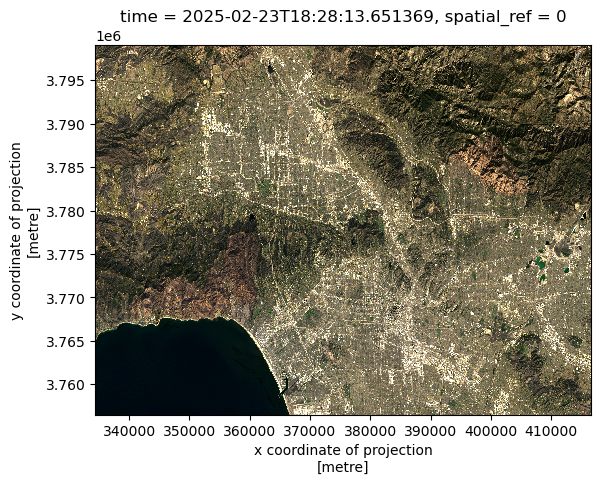

In [124]:
# Image show again
landsat[['red','green','blue']].to_dataarray(dim='band').plot.imshow(
    x='x',
    y='y',
    rgb='band',
    robust = True
)

Explanation comparing outputs for parts (a) and (e):

While there is no visible differences between the images in parts (a) and (e), from our analysis we know that the blue band has 109 missing values, and the green band has one missing value. This would mean that these pixels will not have the true RGB colors. However, the resolution is high, so it is hard to tell on the map.

## 6. False color image


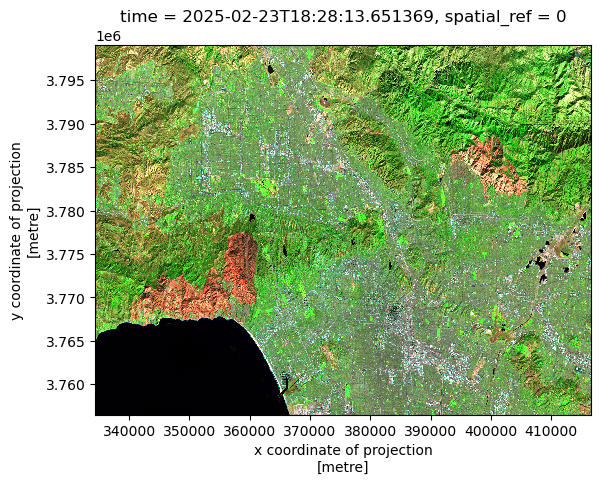

In [44]:
landsat[['swir22','nir08','red']].to_dataarray(dim='band').plot.imshow(
    x='x',y='y',rgb='band',robust=True
)

## 7. Map

In [78]:
# Reproject CRS
fire_perimeter = fire_perimeter.to_crs(landsat.rio.crs)

assert landsat.rio.crs == fire_perimeter.crs, "CRS do not match"

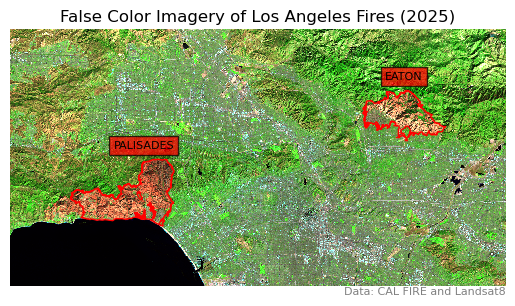

In [102]:
fig, ax = plt.subplots()

# plot false color imagery first
landsat[['swir22','nir08','red']].to_dataarray(dim='band').plot.imshow(ax=ax,
    x='x',y='y',rgb='band',robust=True
)

# plot fire perimeters
fire_perimeter.plot(ax=ax,
                    color='none',
                    edgecolor='red')

# Label each fire
for x, y, name in zip(fire_perimeter.geometry.bounds.maxx, fire_perimeter.geometry.bounds.maxy, fire_perimeter.fire_name):
    # ax.annotate(name, xy=(x-10000,y), xytext=(6, 6), textcoords='offset points', facecolor='red')
    ax.text(x-10000, y+1750, name, bbox={'facecolor':'red','alpha':0.75,'pad':3}, fontsize=8)

ax.set_title('False Color Imagery of Los Angeles Fires (2025)')

# Remove axis and labels
ax.axis('off')
ax.set_xlabel('')
ax.set_ylabel('')

# Data source credits
ax.annotate('Data: CAL FIRE and Landsat8',xy=(1,0), xycoords='axes fraction', ha='right',va='top',fontsize=8,color='gray')

plt.show()


The red lines represents the borders of the respective fires. Through this false color imagery, we can see the difference between the burn areas, which appear more reddish in color, compared to non-burn areas, which appear more green in color. The brightness of the red is due to the high reflectance of shortwave infrared off of the soil, therefore false color imagery makes it easier to identify these areas. The fire perimeter for the Palisades fire is smaller than the red burn scar, and the Eaton fire perimeter is larger than the burn scar.